Dataset Loaded Successfully!
Random Forest Model Loaded!

Prediction Explanation:
-0.16 < cp <= 0.87                       0.1592
thalach > 0.71                           -0.0689
thal <= -0.88                            -0.0530
0.16 < age <= 0.72                       0.0413
exang <= -0.70                           -0.0307
-0.10 < chol <= 0.53                     0.0249
-0.98 < restecg <= 1.02                  0.0247
fbs <= -0.41                             0.0174
-0.05 < trestbps <= 0.51                 0.0134
ca <= -0.69                              -0.0053

LIME Explanation Saved Successfully!

Location:
../reports/lime_explanation.html

LIME Analysis Completed Successfully!


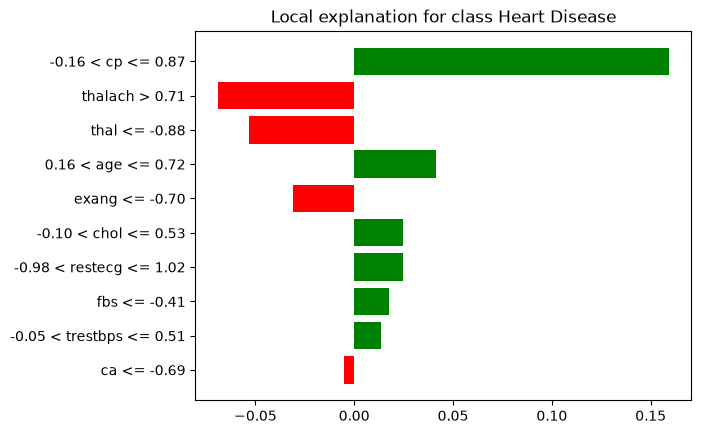

In [2]:
# ==========================================
# LIME EXPLAINABILITY
# ==========================================

# ==========================================
# Step 1 : Import Libraries
# ==========================================

import pandas as pd
import joblib
import lime
import lime.lime_tabular

from sklearn.model_selection import train_test_split

# ==========================================
# Step 2 : Load Dataset
# ==========================================

df = pd.read_csv("../datasets/processed/heart_preprocessed.csv")

print("Dataset Loaded Successfully!")

# ==========================================
# Step 3 : Separate Features and Target
# ==========================================

X = df.drop("target", axis=1)
y = df["target"]

# ==========================================
# Step 4 : Train Test Split
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# ==========================================
# Step 5 : Load Scaler
# ==========================================

scaler = joblib.load("../models/scaler.pkl")

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ==========================================
# Step 6 : Load Best Model
# ==========================================

model = joblib.load("../models/random_forest.pkl")

print("Random Forest Model Loaded!")

# ==========================================
# Step 7 : Create LIME Explainer
# ==========================================

explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train_scaled,
    feature_names=X.columns.tolist(),
    class_names=["No Heart Disease", "Heart Disease"],
    mode="classification"
)

# ==========================================
# Step 8 : Explain One Prediction
# ==========================================

explanation = explainer.explain_instance(
    X_test_scaled[0],
    model.predict_proba,
    num_features=10
)

# ==========================================
# Step 9 : Display Explanation
# ==========================================

print("\nPrediction Explanation:")

for feature, weight in explanation.as_list():
    print(f"{feature:40} {weight:.4f}")

# ==========================================
# Step 10 : Save Explanation as HTML
# ==========================================

explanation.save_to_file(
    "../reports/lime_explanation.html"
)

print("\nLIME Explanation Saved Successfully!")

print("\nLocation:")
print("../reports/lime_explanation.html")

# ==========================================
# Step 11 : Show Explanation
# ==========================================

fig = explanation.as_pyplot_figure()

print("\nLIME Analysis Completed Successfully!")